<a href="https://colab.research.google.com/github/Akash14-09/College_Prjoects/blob/main/Power_systems1_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import requests
import os

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Download dataset
url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"

response = requests.get(url)
with open("power_consumption.zip", "wb") as f:
    f.write(response.content)

# Extract dataset
with zipfile.ZipFile("power_consumption.zip", "r") as zip_ref:
    zip_ref.extractall("power_data")

# Load data
file_path = "power_data/household_power_consumption.txt"

df = pd.read_csv(
    file_path,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [3]:
# Combine Date and Time
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True,
    errors="coerce"
)

# Convert power column to numeric
df["Global_active_power"] = pd.to_numeric(
    df["Global_active_power"],
    errors="coerce"
)

# Remove missing values
df = df.dropna(subset=[
    "Datetime",
    "Global_active_power"
])

# Set datetime as index
df = df.set_index("Datetime")

# Convert minute-level readings into hourly average load
hourly_data = df["Global_active_power"].resample("h").mean()

# Fill missing hourly readings
hourly_data = hourly_data.interpolate(method="time")

print("Preprocessing completed!")
print("Hourly records:", len(hourly_data))

hourly_data.head()

Preprocessing completed!
Hourly records: 34589


,Global_active_power
Datetime,
2006-12-16 17:00:00,4.222889
2006-12-16 18:00:00,3.632200
2006-12-16 19:00:00,3.400233
2006-12-16 20:00:00,3.268567
2006-12-16 21:00:00,3.056467


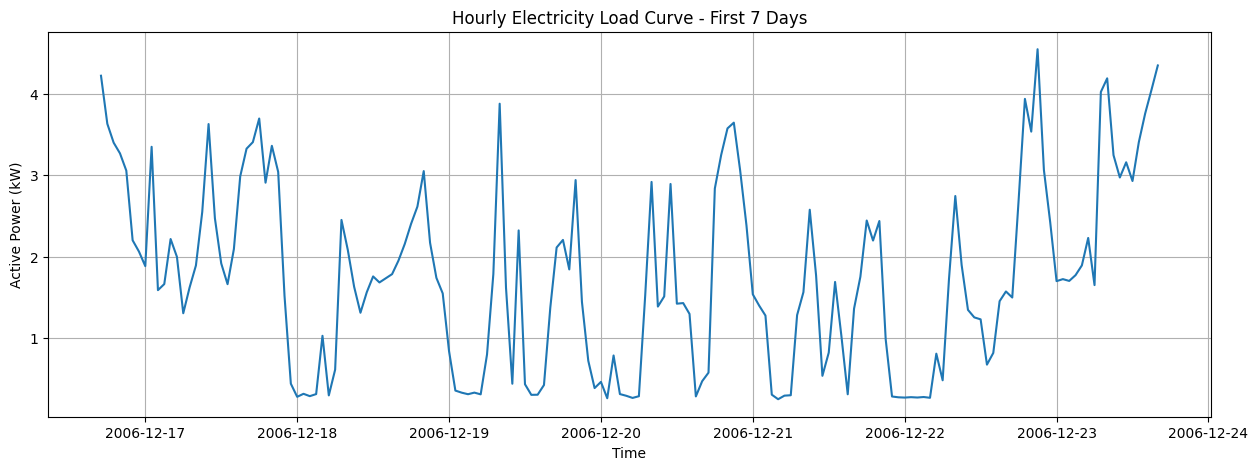

In [4]:
plt.figure(figsize=(15, 5))

plt.plot(hourly_data.iloc[:168])

plt.title("Hourly Electricity Load Curve - First 7 Days")
plt.xlabel("Time")
plt.ylabel("Active Power (kW)")

plt.grid()
plt.show()

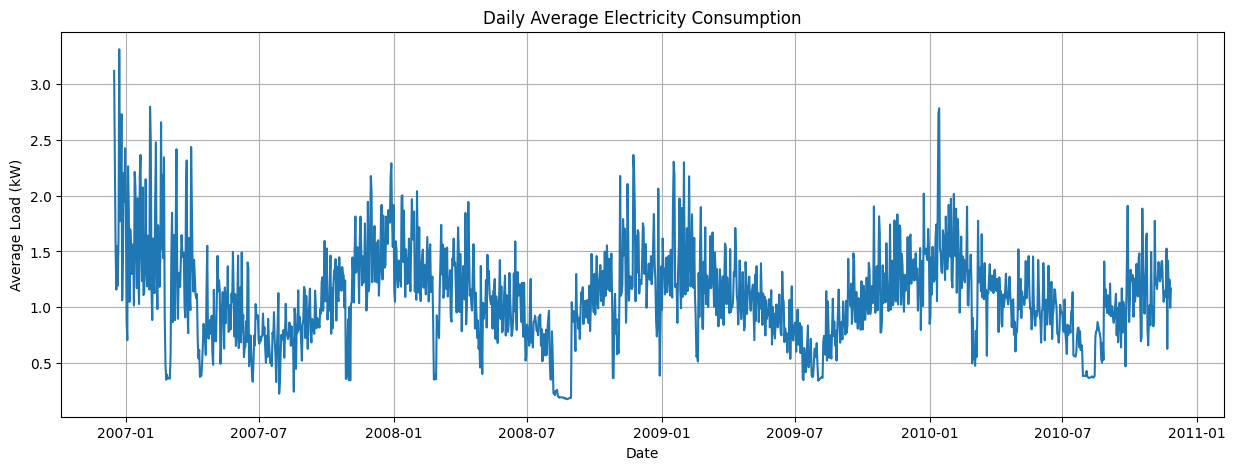

In [5]:
# Daily average load
daily_load = hourly_data.resample("D").mean()

plt.figure(figsize=(15, 5))

plt.plot(daily_load)

plt.title("Daily Average Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Average Load (kW)")

plt.grid()
plt.show()

In [6]:
data = pd.DataFrame(index=hourly_data.index)

data["load"] = hourly_data

# Time-based features
data["hour"] = data.index.hour
data["day"] = data.index.day
data["month"] = data.index.month
data["dayofweek"] = data.index.dayofweek

# Previous load values
data["lag_1"] = data["load"].shift(1)
data["lag_2"] = data["load"].shift(2)
data["lag_3"] = data["load"].shift(3)
data["lag_24"] = data["load"].shift(24)
data["lag_168"] = data["load"].shift(168)

# Rolling average
data["rolling_24"] = data["load"].shift(1).rolling(24).mean()

# Target: next hour load
data["target"] = data["load"].shift(-1)

data = data.dropna()

X = data.drop(columns=["load", "target"])
y = data["target"]

print("Feature engineering completed!")
print("Features:", X.shape)
print("Target:", y.shape)

Feature engineering completed!
Features: (34420, 10)
Target: (34420,)


In [7]:
split = int(len(data) * 0.80)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 27536
Testing samples: 6884


In [8]:
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [9]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("---------------------------")
print("MAE :", round(mae, 4), "kW")
print("RMSE:", round(rmse, 4), "kW")
print("R2 Score:", round(r2, 4))

MODEL PERFORMANCE
---------------------------
MAE : 0.4058 kW
RMSE: 0.5629 kW
R2 Score: 0.4009


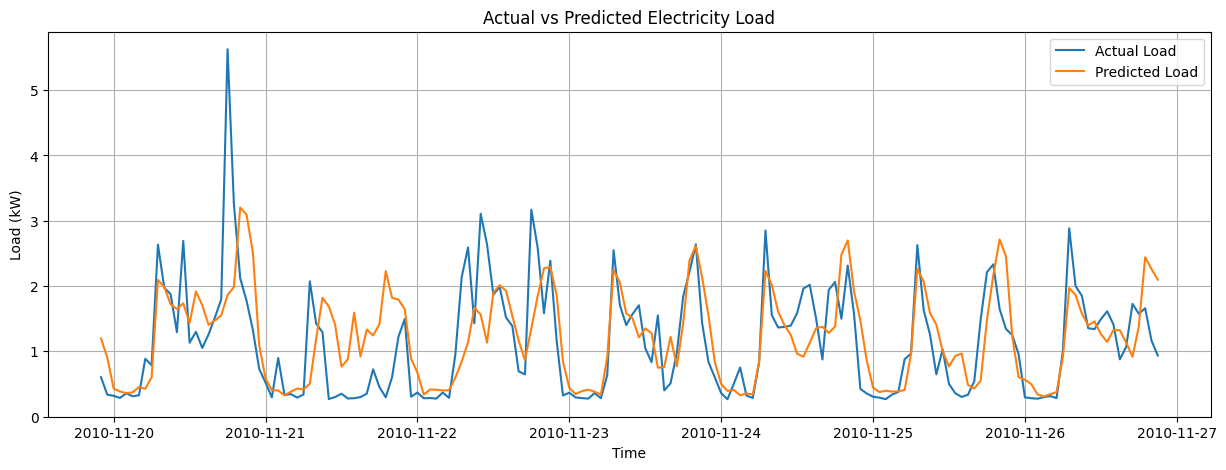

In [10]:
# Compare the last 7 days of test data
plt.figure(figsize=(15, 5))

plt.plot(
    y_test.index[-168:] + pd.Timedelta(hours=1),
    y_test.values[-168:],
    label="Actual Load"
)

plt.plot(
    y_test.index[-168:] + pd.Timedelta(hours=1),
    y_pred[-168:],
    label="Predicted Load"
)

plt.title("Actual vs Predicted Electricity Load")
plt.xlabel("Time")
plt.ylabel("Load (kW)")

plt.legend()
plt.grid()
plt.show()

In [11]:
# Historical values used for future predictions
history = hourly_data.copy()

future_predictions = []

for i in range(24):

    current_time = history.index[-1]

    features = pd.DataFrame([{
        "hour": current_time.hour,
        "day": current_time.day,
        "month": current_time.month,
        "dayofweek": current_time.dayofweek,

        "lag_1": history.iloc[-1],
        "lag_2": history.iloc[-2],
        "lag_3": history.iloc[-3],
        "lag_24": history.iloc[-24],
        "lag_168": history.iloc[-168],

        "rolling_24": history.iloc[-24:].mean()
    }])

    # Predict next hour
    prediction = model.predict(features)[0]

    next_time = current_time + pd.Timedelta(hours=1)

    future_predictions.append(prediction)

    # Add prediction to history for next iteration
    history.loc[next_time] = prediction

# Create forecast dataframe
forecast = pd.DataFrame({
    "Datetime": pd.date_range(
        start=hourly_data.index[-1] + pd.Timedelta(hours=1),
        periods=24,
        freq="h"
    ),
    "Predicted Load (kW)": future_predictions
})

forecast

,Datetime,Predicted Load (kW)
0,2010-11-26 22:00:00,1.129211
1,2010-11-26 23:00:00,0.663960
2,2010-11-27 00:00:00,0.645404
3,2010-11-27 01:00:00,0.436220
4,2010-11-27 02:00:00,0.469781
5,2010-11-27 03:00:00,0.451563
6,2010-11-27 04:00:00,0.456009
7,2010-11-27 05:00:00,0.481650
8,2010-11-27 06:00:00,0.644631
9,2010-11-27 07:00:00,1.990035


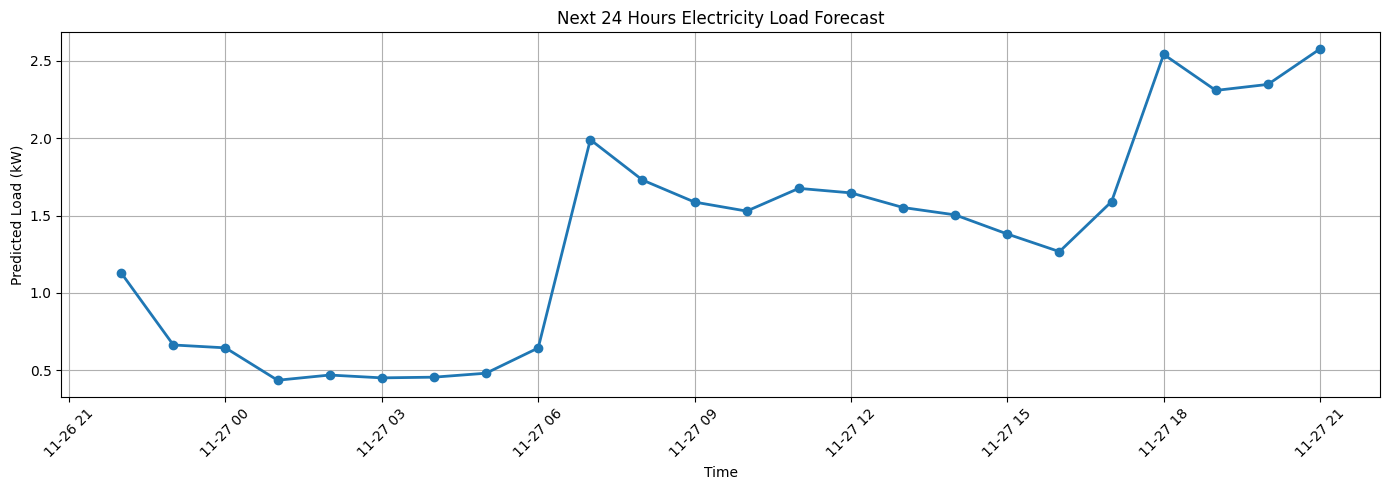

In [12]:
plt.figure(figsize=(14, 5))

plt.plot(
    forecast["Datetime"],
    forecast["Predicted Load (kW)"],
    marker="o",
    linewidth=2
)

plt.title("Next 24 Hours Electricity Load Forecast")
plt.xlabel("Time")
plt.ylabel("Predicted Load (kW)")

plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

In [13]:
predicted_load = forecast["Predicted Load (kW)"]

maximum_demand = predicted_load.max()
average_load = predicted_load.mean()

total_energy = predicted_load.sum()  # kWh for 24 hourly averages

load_factor = average_load / maximum_demand

print("POWER SYSTEM ANALYSIS")
print("-----------------------------")

print("Maximum Demand:",
      round(maximum_demand, 2), "kW")

print("Average Load:",
      round(average_load, 2), "kW")

print("Estimated Energy:",
      round(total_energy, 2), "kWh")

print("Load Factor:",
      round(load_factor * 100, 2), "%")

print("Peak Demand Time:",
      forecast.loc[
          predicted_load.idxmax(), "Datetime"
      ])

POWER SYSTEM ANALYSIS
-----------------------------
Maximum Demand: 2.58 kW
Average Load: 1.36 kW
Estimated Energy: 32.6 kWh
Load Factor: 52.73 %
Peak Demand Time: 2010-11-27 21:00:00


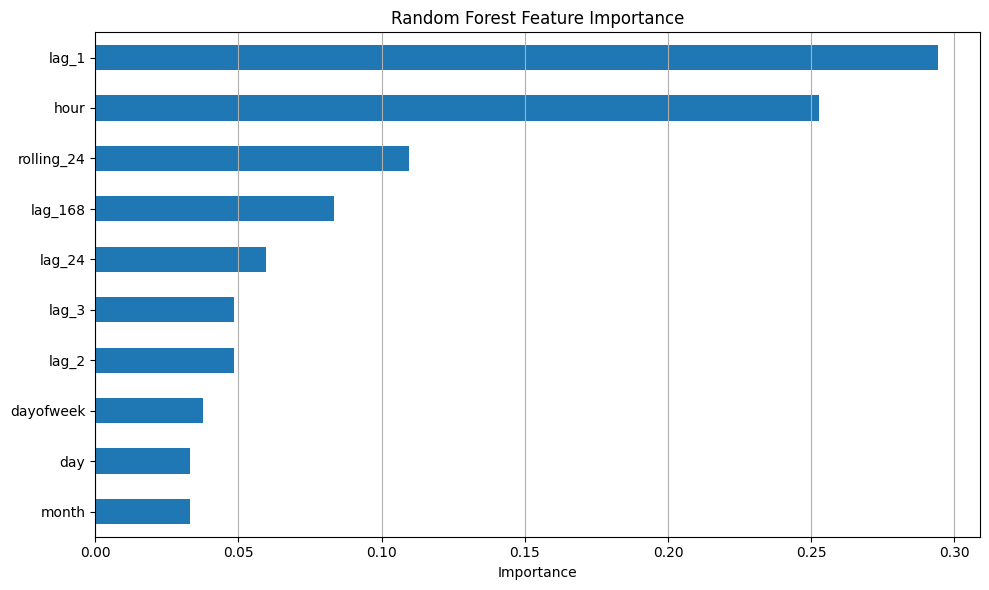

In [14]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(10, 6))

importance.plot(kind="barh")

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")

plt.grid(axis="x")
plt.tight_layout()
plt.show()

In [15]:
forecast.to_csv(
    "Electricity_Load_Forecast.csv",
    index=False
)

from google.colab import files

files.download("Electricity_Load_Forecast.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>